# PS3 · Deutsch–Jozsa
Given a black-box $f:\{0,1\}^n\to\{0,1\}$ promised to be **constant** or **balanced**, decide which. A deterministic classical algorithm needs up to $2^{n-1}+1$ queries. Deutsch–Jozsa needs **one**.

In [1]:
import sys, json, math, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
def sweep(name): return json.load(open(f'../data/sweeps/{name}.json'))
from qrelay import dj, plots, hardware
from qrelay.noise import NoiseSpec
from qiskit.visualization import plot_histogram

## 1. Why it works: superposition → phase kickback → interference
1. **Superposition:** $H^{\otimes n}|0\rangle^{\otimes n} = \frac{1}{\sqrt{2^n}}\sum_x |x\rangle$, and the ancilla is prepared in $|-\rangle$.
2. **Phase kickback:** $U_f|x\rangle|y\rangle = |x\rangle|y\oplus f(x)\rangle$. With $|y\rangle=|-\rangle$: $U_f|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle$. The answer moves into a **phase** on the input, and the ancilla is untouched.
3. **Interference:** after the final $H^{\otimes n}$, the amplitude of $|0\dots0\rangle$ is $\frac{1}{2^n}\sum_x(-1)^{f(x)}$. That is $\pm1$ if $f$ is constant and exactly **0** if balanced.

**Measure all-zeros ⇒ constant; anything else ⇒ balanced.** Qubit layout: inputs 0..n−1 (little-endian, $x=\sum_i x_i2^i$), ancilla n.

## 2. The oracle library (2 constant + 4 balanced, any n)

In [2]:
n = 3
lib = dj.oracle_library(n, seed=0)
for o in lib: print(f"{o.name:12s} {o.kind:9s} truth table {''.join(map(str, o.truth_table))}   2q gates: {o.two_qubit_gate_count()}")

const_0      constant  truth table 00000000   2q gates: 0
const_1      constant  truth table 11111111   2q gates: 0
x0           balanced  truth table 01010101   2q gates: 1
parity       balanced  truth table 01101001   2q gates: 3
ip_011       balanced  truth table 01100110   2q gates: 2
random_bal   balanced  truth table 10100101   2q gates: 56


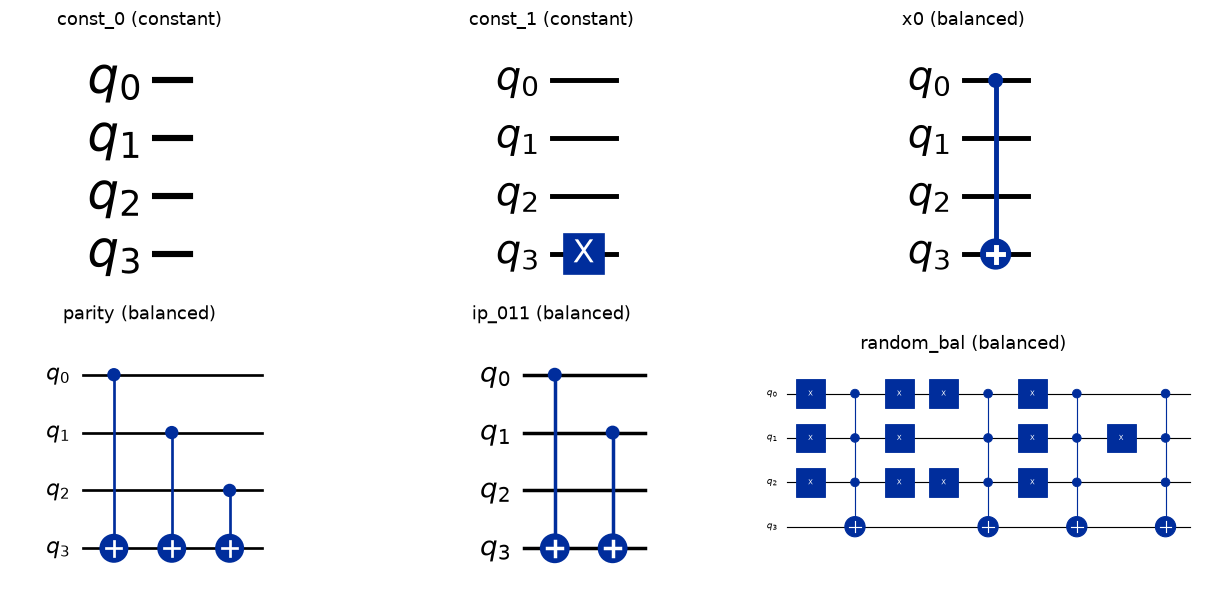

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for ax, o in zip(axes.flat, lib): o.build().draw('mpl', ax=ax); ax.set_title(f'{o.name} ({o.kind})')
plt.tight_layout(); plt.show()

## 3. The full DJ circuit and its measurement results

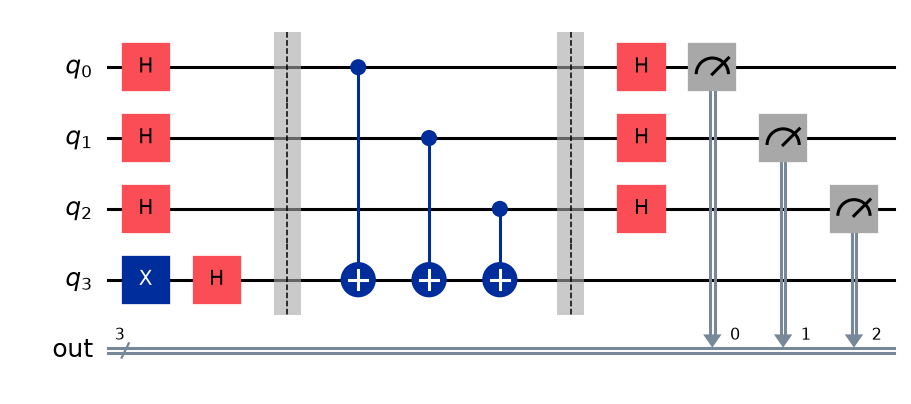

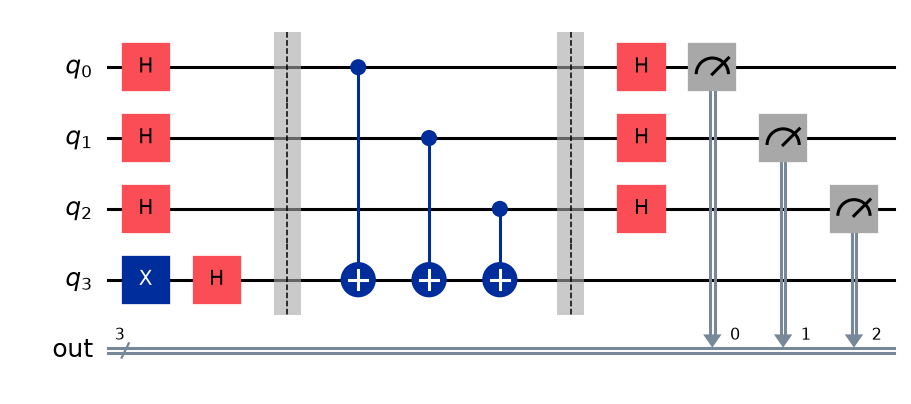

In [4]:
dj.dj_circuit(dj.parity(3)).draw('mpl', fold=-1)

const_0      truth=constant  verdict=constant  P(000)=1.000  OK
const_1      truth=constant  verdict=constant  P(000)=1.000  OK
x0           truth=balanced  verdict=balanced  P(000)=0.000  OK
parity       truth=balanced  verdict=balanced  P(000)=0.000  OK
ip_011       truth=balanced  verdict=balanced  P(000)=0.000  OK
random_bal   truth=balanced  verdict=balanced  P(000)=0.000  OK


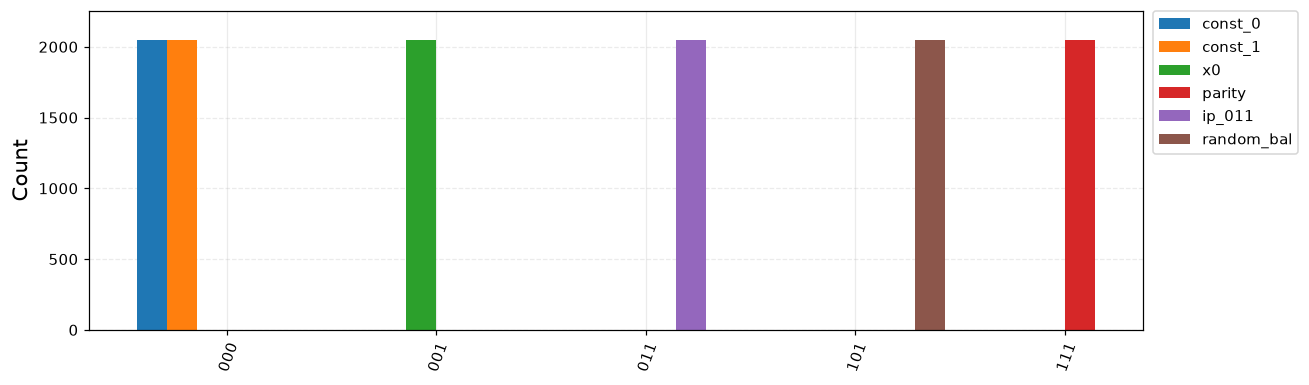

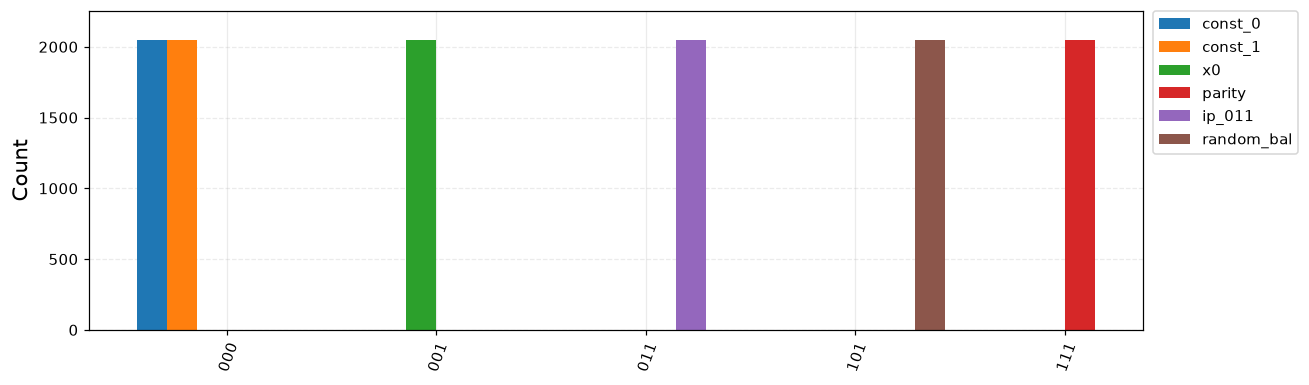

In [5]:
results = {o.name: dj.run_dj(o, shots=2048) for o in lib}
for k, r in results.items(): print(f"{k:12s} truth={r['truth']:9s} verdict={r['verdict']:9s} P(000)={r['p_all_zeros']:.3f}  {'OK' if r['correct'] else 'WRONG'}")
plot_histogram([r['counts'] for r in results.values()], legend=list(results), figsize=(12, 3.6), bar_labels=False)

## 4. Step-through: amplitudes of the input register (balanced vs constant)

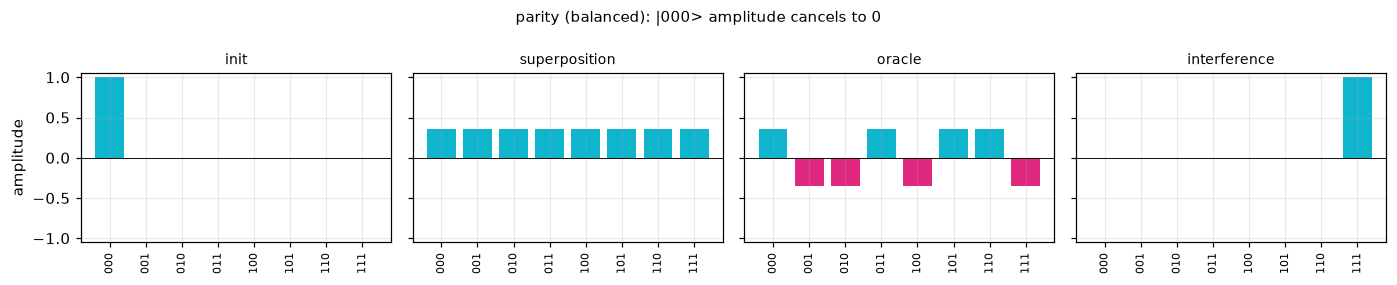

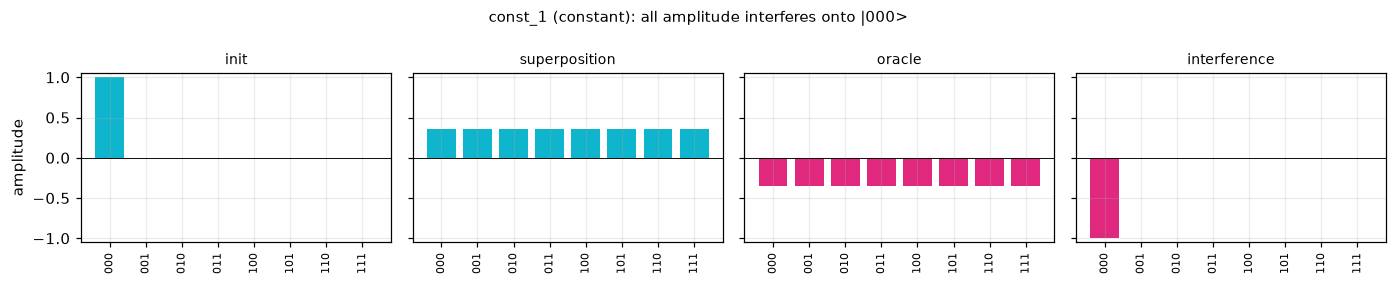

ancilla Bloch vector after the query: [-0.9999999999999993, 0.0, 0.0] (= |->, unchanged: phase kickback)


In [6]:
plots.dj_steps(dj.dj_steps(dj.parity(3)), 3, 'parity (balanced): |000> amplitude cancels to 0'); plt.show()
plots.dj_steps(dj.dj_steps(dj.constant_one(3)), 3, 'const_1 (constant): all amplitude interferes onto |000>'); plt.show()
print('ancilla Bloch vector after the query:', dj.dj_steps(dj.parity(3))[2]['ancilla_bloch'], '(= |->, unchanged: phase kickback)')

## 5. Correctness proof by exhaustion (n = 1, 2, 3) and random testing for larger n
We enumerate **every** constant (2) and **every** balanced function ($\binom{2^n}{2^{n-1}}$ = 2, 6, 70) and check the exact probability of $|0\dots0\rangle$.

In [7]:
import math
for n_ in (1, 2, 3):
    os_ = dj.all_oracles(n_)
    ok = all(abs(dj.p_all_zeros_exact(o) - (1.0 if o.kind == 'constant' else 0.0)) < 1e-9 for o in os_)
    print(f"n={n_}: {len(os_)} functions ({math.comb(2**n_, 2**(n_-1))} balanced), all classified correctly: {ok}")
for n_ in (4, 5, 6, 7, 8):
    k = 300 if n_ <= 6 else 40
    ok = all(dj.p_all_zeros_exact(dj.random_balanced(n_, seed=s)) < 1e-9 for s in range(k))
    print(f"n={n_}: {k} random balanced oracles, all P(0...0)=0: {ok}")

n=1: 4 functions (2 balanced), all classified correctly: True
n=2: 8 functions (6 balanced), all classified correctly: True


n=3: 72 functions (70 balanced), all classified correctly: True


n=4: 300 random balanced oracles, all P(0...0)=0: True


n=5: 300 random balanced oracles, all P(0...0)=0: True


n=6: 300 random balanced oracles, all P(0...0)=0: True


n=7: 40 random balanced oracles, all P(0...0)=0: True


n=8: 40 random balanced oracles, all P(0...0)=0: True


## 6. Query complexity, verified by an adversary simulation
The adversary answers 0 to the first $2^{n-1}$ distinct queries, which stays consistent with both 'constant 0' and some balanced function, so no deterministic algorithm can stop earlier.

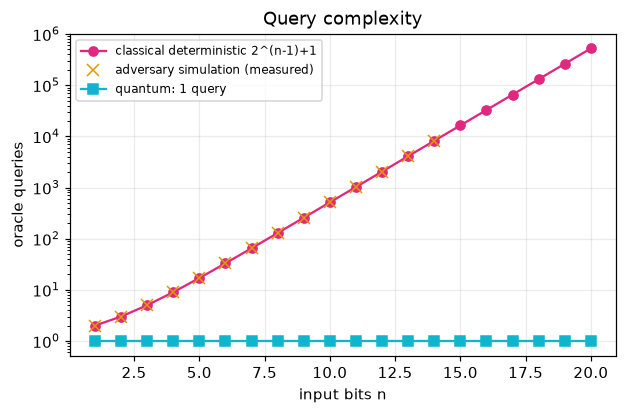

n | quantum | classical worst | adversary-measured
1 1 2 2
2 1 3 3
3 1 5 5
4 1 9 9
5 1 17 17
6 1 33 33
7 1 65 65
8 1 129 129
9 1 257 257
10 1 513 513


[None, None, None, None, None, None, None, None, None, None]

In [8]:
rows = dj.complexity_table(20)
plots.complexity(rows); plt.show()
print('n | quantum | classical worst | adversary-measured'); [print(r['n'], 1, r['classical_worst'], r['adversary']) for r in rows[:10]]

## 7. Noise: deeper oracles degrade faster
Caveat: under strong noise the output tends to uniform, so P(all-zeros) → 2⁻ⁿ. Constant oracles then fail, while balanced ones 'succeed' with probability 1−2⁻ⁿ **by chance**. The discrimination $P_0(\text{const})-P_0(\text{bal})$ removes that artefact.

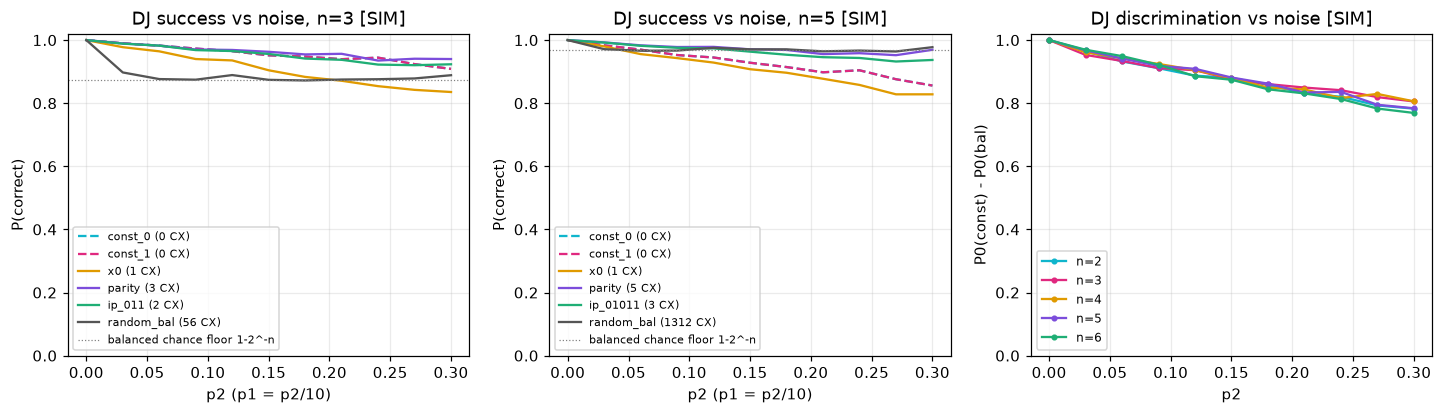

In [9]:
data = sweep('dj_noise')
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
plots.dj_noise(data, '3', ax=ax[0]); plots.dj_noise(data, '5', ax=ax[1]); plots.dj_discrimination(data, ax=ax[2]); plt.show()

## 8. Real-device / emulated results

In [10]:
for src in ('HW', 'EMU'):
    rec = hardware.latest(src)
    if rec is None: print(f'[{src}] not available'); continue
    a = hardware.analyze(rec); print(f"[{src}] {a['backend']} job={a['job_id']}")
    for d in a['dj']: print(f"   {d['tag']:22s} truth={d['truth']:9s} verdict={d['verdict']:9s} success={d['success_probability']:.3f}  2q gates={d['two_qubit_gates']}")

[HW] ibm_marrakesh job=dbgnmpote5oc738iia1g
   dj_n2_const_0          truth=constant  verdict=constant  success=0.993  2q gates=0
   dj_n2_const_1          truth=constant  verdict=constant  success=0.989  2q gates=0
   dj_n2_parity           truth=balanced  verdict=balanced  success=0.992  2q gates=2
   dj_n2_random_bal       truth=balanced  verdict=balanced  success=0.888  2q gates=19
   dj_n3_const_0          truth=constant  verdict=constant  success=0.986  2q gates=0
   dj_n3_const_1          truth=constant  verdict=constant  success=0.983  2q gates=0
   dj_n3_parity           truth=balanced  verdict=balanced  success=0.998  2q gates=3
   dj_n3_random_bal       truth=balanced  verdict=balanced  success=0.855  2q gates=75
   distdj_n2_const_1      truth=constant  verdict=constant  success=0.996  2q gates=2
   distdj_n2_parity       truth=balanced  verdict=balanced  success=0.861  2q gates=4
[EMU] fake_brisbane job=None
   dj_n2_const_0          truth=constant  verdict=constant  succe

## Conclusions
* DJ is exhaustively correct for n ≤ 3 and tested on hundreds of random balanced oracles up to n = 8.
* 1 query versus $2^{n-1}+1$, a gap confirmed by an adversary simulation.
* Noise hurts oracles in proportion to their entangling-gate count. Random balanced oracles (MCX-built) degrade fastest.